# Module 11: Sequence Modeling with RNN, LSTM, and GRU

This notebook teaches **Sequence Modeling with RNN, LSTM, and GRU** from basic intuition to practical deep-learning use.

Main coverage: sequence data, RNN hidden state, BPTT, vanishing gradients, LSTM gates, GRU gates, bidirectional models, teacher forcing.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Module Outline

* **Step 1: Sequence data**
* **Step 2: Task shapes**
* **Step 3: RNN hidden state**
* **Step 4: Backpropagation through time**
* **Step 5: Vanishing gradients**
* **Step 6: LSTM forget input candidate output gates**
* **Step 7: GRU update and reset gates**
* **Step 8: Bidirectional RNN**
* **Step 9: Stacked RNN**
* **Step 10: Teacher forcing**
* **Step 11: Forecasting example**


## Step 2: Task shapes

**What is it?** Task shapes is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 3: RNN hidden state

**What is it?** RNN hidden state is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 4: Backpropagation through time

**What is it?** Backpropagation through time is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 5: Vanishing gradients

**What is it?** Vanishing gradients is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 6: LSTM forget input candidate output gates

**What is it?** LSTM forget input candidate output gates is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 7: GRU update and reset gates

**What is it?** GRU update and reset gates is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 8: Bidirectional RNN

**What is it?** Bidirectional RNN is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 9: Stacked RNN

**What is it?** Stacked RNN is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 10: Teacher forcing

**What is it?** Teacher forcing is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


## Step 11: Forecasting example

**What is it?** Forecasting example is one of the core concepts in this module.

**Where it is used:** It appears in real deep learning workflows when designing models, training them, debugging them, or deploying them.

**Why it matters:** The concept helps explain how data moves through a network, how parameters are learned, how predictions are evaluated, or how models are made reliable.

**Simple intuition:** Treat this concept as one component in the full pipeline: data → tensor → model → loss → optimization → evaluation → deployment.

**Common mistake:** memorizing the term without connecting it to tensor shapes, model behavior, validation, or practical failure modes.


(75, 5) (75,)


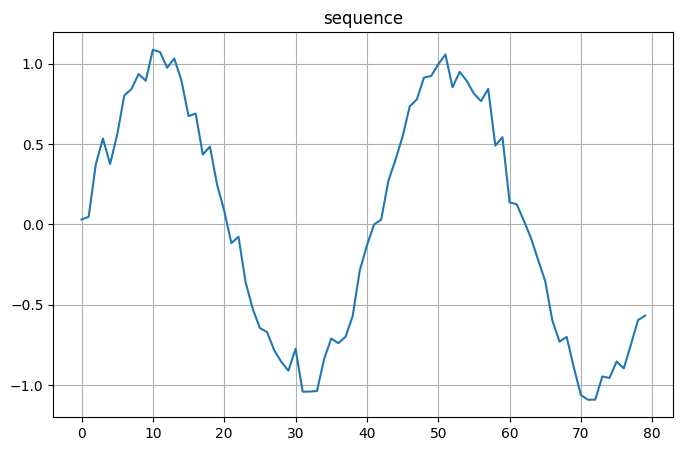

In [2]:
series=np.sin(np.linspace(0,12,80))+.1*rng.normal(size=80); window=5; Xseq=np.array([series[i:i+window] for i in range(len(series)-window)]); ynext=np.array([series[i+window] for i in range(len(series)-window)]); print(Xseq.shape,ynext.shape); plt.plot(series); plt.title('sequence'); plt.show()


In [3]:
Wx=rng.normal(size=(1,3)); Wh=rng.normal(size=(3,3)); b=rng.normal(size=(3,)); h=np.zeros(3); rows=[]
for t,x in enumerate(series[:6]): h=np.tanh(np.array([x])@Wx+h@Wh+b); rows.append({'t':t,'input':x,'h1':h[0],'h2':h[1],'h3':h[2]})
display(pd.DataFrame(rows).round(3))


,t,input,h1,h2,h3
0,0,0.030,-0.388,-0.100,-0.935
1,1,0.047,-0.554,-0.264,-0.952
2,2,0.374,-0.329,-0.292,-0.972
3,3,0.534,-0.337,-0.598,-0.970
4,4,0.376,-0.269,-0.521,-0.975
5,5,0.558,-0.251,-0.655,-0.975


## Research-Backed Coverage Expansion: Sequence Modeling with RNN, LSTM, and GRU

This expansion fills concepts commonly covered in deep-learning texts and courses such as the Deep Learning book, CS231n/CS224n, and Dive into Deep Learning. Each concept is written for learning flow: definition, where it is used, why it matters, and common mistakes.


### Sequence Length

**Definition:** Number of time steps or tokens in an input.

**Where it is used:** Text, time series, audio, events.

**Why it matters:** Controls memory, compute, and gradient path length.

**Common mistake:** Ignoring padding/masking with variable lengths.


### Many-to-One Task

**Definition:** A whole sequence maps to one output.

**Where it is used:** Sentiment classification, sequence-level diagnosis.

**Why it matters:** Final or pooled state represents the sequence.

**Common mistake:** Using per-token loss for one sequence label.


### Many-to-Many Task

**Definition:** Each time step maps to an output or another sequence.

**Where it is used:** Tagging, translation, forecasting.

**Why it matters:** Output shape must match task shape.

**Common mistake:** Confusing aligned and unaligned sequence outputs.


### Hidden State as Memory

**Definition:** A recurrent state carries information from earlier steps.

**Where it is used:** RNN/LSTM/GRU.

**Why it matters:** It lets current prediction depend on past context.

**Common mistake:** Assuming it stores unlimited history perfectly.


### Truncated BPTT

**Definition:** Backpropagation through only a limited number of time steps.

**Where it is used:** Long sequence training.

**Why it matters:** Reduces memory and compute but limits long-range credit assignment.

**Common mistake:** Truncating too short for the task.


### Teacher Forcing Ratio

**Definition:** Probability of feeding true previous output during training.

**Where it is used:** Seq2seq training.

**Why it matters:** Speeds training but can create exposure bias.

**Common mistake:** Using full teacher forcing then failing at inference.


### Exposure Bias

**Definition:** Model sees true previous tokens in training but its own mistakes in inference.

**Where it is used:** Autoregressive generation.

**Why it matters:** Errors can compound during generation.

**Common mistake:** Evaluating only teacher-forced loss.


### Packed/Padded Sequences

**Definition:** Batching variable-length sequences with padding and masks.

**Where it is used:** NLP and time series.

**Why it matters:** Prevents padding tokens from becoming fake data.

**Common mistake:** Letting loss include padded positions.


### Stateful vs Stateless RNN

**Definition:** Stateful keeps hidden state across batches; stateless resets it.

**Where it is used:** Streaming and long time series.

**Why it matters:** Stateful mode can preserve continuity.

**Common mistake:** Accidentally leaking state between unrelated sequences.


### Attention over RNN States

**Definition:** Decoder can attend to all encoder states instead of only final state.

**Where it is used:** Seq2seq and translation history.

**Why it matters:** Improves long sequence handling.

**Common mistake:** Thinking attention requires transformers only.


### Gradient Clipping for RNNs

**Definition:** Limits large gradients during sequence training.

**Where it is used:** RNN/LSTM/GRU training.

**Why it matters:** Prevents unstable updates from exploding gradients.

**Common mistake:** Using clipping without monitoring root cause.


### Forecasting Leakage

**Definition:** Using future values or future-derived features during training.

**Where it is used:** Time-series forecasting.

**Why it matters:** Leakage gives fake performance.

**Common mistake:** Random split on time-dependent data.


input windows shape: (68, 12) target shape: (68,)


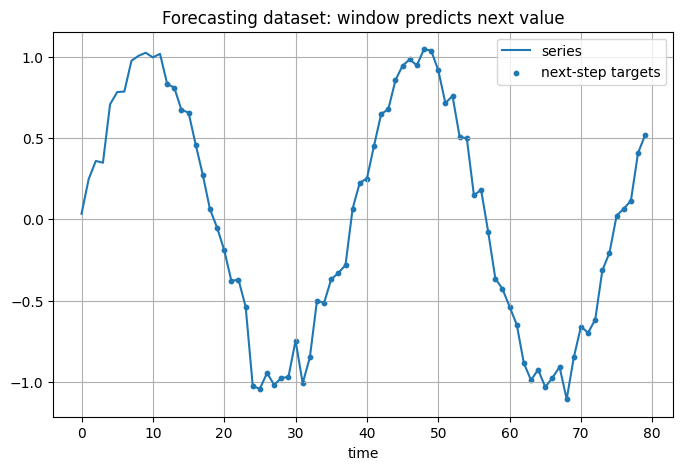

In [4]:
import numpy as np, matplotlib.pyplot as plt
t = np.arange(80)
series = np.sin(t/6) + 0.1*np.random.default_rng(1).normal(size=len(t))
window = 12
X = np.array([series[i:i+window] for i in range(len(series)-window)])
y = np.array([series[i+window] for i in range(len(series)-window)])
plt.plot(t, series, label='series')
plt.scatter(np.arange(window, len(series)), y, s=10, label='next-step targets')
plt.title('Forecasting dataset: window predicts next value')
plt.xlabel('time'); plt.legend();
print('input windows shape:', X.shape, 'target shape:', y.shape)


## Algorithm and Dataset Expansion: Sequence Algorithms and Datasets

This section connects the concepts to algorithms and datasets. For each module, the learner should understand what data shape is appropriate, which algorithm family fits the data, what metric to read, and what failure pattern to check.


### Sequence Algorithm Map

| Algorithm | Core mechanism | Good for | Limitation |
|---|---|---|---|
| Vanilla RNN | recurrent hidden state | short sequence demos | vanishing gradients |
| LSTM | input/forget/output gates and cell state | longer dependencies | more parameters |
| GRU | update/reset gates | simpler gated recurrence | less expressive than LSTM in some tasks |
| Bidirectional RNN | reads forward and backward | tagging/classification with full sequence | not valid for causal forecasting |
| Seq2Seq | encoder state feeds decoder | translation/summarization history | bottleneck without attention |
| Attention RNN | decoder attends to encoder states | longer source sequences | slower than transformer attention in parallelization |


### Dataset Explanation

Use **forecasting windows** for time-series and **token sequences** for text. Explain the sample shape carefully:

* time series window: `(batch, time_steps, features)`;
* text after tokenization: `(batch, sequence_length)`;
* sequence labeling target: `(batch, sequence_length)`;
* sequence classification target: `(batch,)`.

Do not use random splits for true forecasting; use past-to-future splits.


In [5]:
import numpy as np, pandas as pd
series=np.arange(20)
window=5
rows=[]
for i in range(len(series)-window):
    rows.append({'input_window':series[i:i+window].tolist(),'target_next':series[i+window]})
display(pd.DataFrame(rows[:6]))


,input_window,target_next
0,"[0, 1, 2, 3, 4]",5
1,"[1, 2, 3, 4, 5]",6
2,"[2, 3, 4, 5, 6]",7
3,"[3, 4, 5, 6, 7]",8
4,"[4, 5, 6, 7, 8]",9
5,"[5, 6, 7, 8, 9]",10


## Complete Concept and Algorithm Coverage: Module 11 — Sequence Models

This section is a fuller checklist for the module. It is written so the learner can see not only the main concept, but also related algorithms, variants, correct datasets, metrics, and common failure modes.


| Area | Concepts / algorithms | What the student must understand |
|---|---|---|
| Sequence data types | text tokens, audio frames, sensor streams, event logs, financial series | A sequence is ordered data; order changes meaning. |
| RNN variants | Elman RNN, LSTM, GRU, peephole LSTM, bidirectional RNN, stacked RNN | Gates help preserve information over time. |
| Seq2Seq algorithms | encoder-decoder, attention seq2seq, beam search, teacher forcing, scheduled sampling | Used for output sequences such as translation or summarization. |
| Forecasting models | autoregressive windows, sequence-to-one, sequence-to-sequence forecasting, direct multi-horizon forecasting | Forecasting target shape must be explained. |
| Training mechanics | BPTT, truncated BPTT, masking, padding, packed sequences, stateful training | Variable-length sequences need masks or packed handling. |
| Generation mechanics | greedy decoding, beam search, top-k/top-p sampling, temperature | Decoding algorithm changes generated sequence behavior. |
| Losses/metrics | cross-entropy, perplexity, MAE/RMSE/MAPE for forecasting, WER for speech | Metric depends on sequence task. |
| Failure modes | vanishing gradients, exposure bias, teacher-forcing mismatch, leakage, compounding forecast error | Sequence models fail in task-specific ways. |
| Dataset choice | character text for RNNs, IMDB sentiment, weather/energy forecasting, speech frames | Choose data where order matters. |


### Correct learning flow

Teach sequence shape first. Then teach recurrence and hidden state. Then gates. Then training through time. Then decoding and forecasting-specific evaluation.


In [6]:
import pandas as pd
seq_shapes = pd.DataFrame({
    'task':['sentiment classification','token tagging','next-token language model','one-step forecasting','multi-horizon forecasting'],
    'input_shape':['batch x time','batch x time','batch x time','batch x window x features','batch x window x features'],
    'target_shape':['batch','batch x time','batch x time shifted','batch','batch x horizon']
})
display(seq_shapes)


,task,input_shape,target_shape
0,sentiment classification,batch x time,batch
1,token tagging,batch x time,batch x time
2,next-token language model,batch x time,batch x time shifted
3,one-step forecasting,batch x window x features,batch
4,multi-horizon forecasting,batch x window x features,batch x horizon


## Module 11 Summary

This module covered **Sequence Modeling with RNN, LSTM, and GRU** from foundation to advanced orientation. Review each step until you can explain what it is, where it is used, why it matters, and how the code/visual connects to the idea.
